In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torchvision
import torch.nn.functional as F
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

train_df = pd.read_csv("mass_case_description_train_set.csv")
test_df = pd.read_csv("mass_case_description_test_set.csv")
# print(train_df.head(), "Head")
# print(train_df.columns, "Columns")
print(train_df.shape, "Shape")

(1318, 14) Shape


In [2]:
import torch

print(torch.cuda.is_available())
# print(torch.cuda.get_device_name(0))
print(torch.cuda.device_count())

True
1


In [3]:
train_df["label"] = train_df["pathology"].map({
    "BENIGN": 0,
    "BENIGN_WITHOUT_CALLBACK": 0,
    "MALIGNANT": 1
})

test_df["label"] = test_df["pathology"].map({
     "BENIGN": 0,
     "BENIGN_WITHOUT_CALLBACK": 0,
     "MALIGNANT": 1
})

train_df.head()
# print(train_df.shape)

,patient_id,breast_density,left or right breast,image view,abnormality id,abnormality type,mass shape,mass margins,assessment,pathology,subtlety,image file path,cropped image file path,ROI mask file path,label
0,P_00001,3,LEFT,CC,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00001_LEFT_CC_1/1.3.6.1.4.1.95...,1
1,P_00001,3,LEFT,MLO,1,mass,IRREGULAR-ARCHITECTURAL_DISTORTION,SPICULATED,4,MALIGNANT,4,Mass-Training_P_00001_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00001_LEFT_MLO_1/1.3.6.1.4.1.9...,1
2,P_00004,3,LEFT,CC,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_CC/1.3.6.1.4.1.9590...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,Mass-Training_P_00004_LEFT_CC_1/1.3.6.1.4.1.95...,0
3,P_00004,3,LEFT,MLO,1,mass,ARCHITECTURAL_DISTORTION,ILL_DEFINED,4,BENIGN,3,Mass-Training_P_00004_LEFT_MLO/1.3.6.1.4.1.959...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,Mass-Training_P_00004_LEFT_MLO_1/1.3.6.1.4.1.9...,0
4,P_00004,3,RIGHT,MLO,1,mass,OVAL,CIRCUMSCRIBED,4,BENIGN,5,Mass-Training_P_00004_RIGHT_MLO/1.3.6.1.4.1.95...,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,Mass-Training_P_00004_RIGHT_MLO_1/1.3.6.1.4.1....,0


In [ ]:
from azureml.fsspec import AzureMachineLearningFileSystem

fs = AzureMachineLearningFileSystem(azure_path)

dicom_files = fs.glob("**/*.dcm")
print(f"Found {len(dicom_files)} DICOM files")

/anaconda/envs/azureml_py310_sdkv2/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Overriding of current MeterProvider is not allowed
Overriding of current TracerProvider is not allowed
Overriding of current LoggerProvider is not allowed
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented
Attempting to instrument while already instrumented


Found 10643 DICOM files


In [5]:
import io
import pydicom

# Keep only real Mass-Training DICOM files
mass_dcm_files = [
    p for p in dicom_files
    if p.lower().endswith(".dcm")
    and ("Mass-Training_" in p or "Mass-Test_" in p)
]
print(f"Mass DICOM files: {len(mass_dcm_files)}")

dcm_lookup = {}

for i, path in enumerate(mass_dcm_files):

    if i % 200 == 0:
        print(f"Processing {i}/{len(mass_dcm_files)}")

    try:
        parts = path.split("/")
        idx = parts.index("cbis_ddsm")
        case_folder = parts[idx + 1]
    
        # Remove trailing "_1" if present
        if case_folder.endswith("_1"):
         case_folder = case_folder[:-2]

        with fs.open(path, "rb") as f:
         ds = pydicom.dcmread(f, stop_before_pixels=True)
        area = ds.Rows * ds.Columns

        if (
            case_folder not in dcm_lookup
            or area > dcm_lookup[case_folder][0]
        ):
            dcm_lookup[case_folder] = (area, path)

    except Exception as e:
        print(f"Skipping: {path}")
        continue
print(f"\nMass lookup contains {len(dcm_lookup)} cases.")

Mass DICOM files: 4984
Processing 0/4984
Processing 200/4984
Processing 400/4984
Processing 600/4984
Processing 800/4984
Processing 1000/4984
Processing 1200/4984
Processing 1400/4984
Processing 1600/4984
Processing 1800/4984
Processing 2000/4984
Processing 2200/4984
Processing 2400/4984
Processing 2600/4984
Processing 2800/4984
Processing 3000/4984
Processing 3200/4984
Processing 3400/4984
Processing 3600/4984
Processing 3800/4984
Processing 4000/4984
Processing 4200/4984
Processing 4400/4984
Processing 4600/4984
Processing 4800/4984

Mass lookup contains 1718 cases.


In [6]:
# match image with csv row
test_df["dcm_path"] = test_df["image file path"].apply(
    lambda x: dcm_lookup[x.split("/")[0].removesuffix("_1")][1]
)

train_df["dcm_path"] = train_df["image file path"].apply(
    lambda x: dcm_lookup[x.split("/")[0].removesuffix("_1")][1]
)

print("Mass-Test_P_00016_LEFT_CC" in dcm_lookup)
print("Mass-Test_P_00016_LEFT_MLO" in dcm_lookup)
print("Missing paths:", test_df["dcm_path"].isna().sum())
print(train_df.head())

True
True
Missing paths: 0
  patient_id  breast_density left or right breast image view  abnormality id  \
0    P_00001               3                 LEFT         CC               1   
1    P_00001               3                 LEFT        MLO               1   
2    P_00004               3                 LEFT         CC               1   
3    P_00004               3                 LEFT        MLO               1   
4    P_00004               3                RIGHT        MLO               1   

  abnormality type                          mass shape   mass margins  \
0             mass  IRREGULAR-ARCHITECTURAL_DISTORTION     SPICULATED   
1             mass  IRREGULAR-ARCHITECTURAL_DISTORTION     SPICULATED   
2             mass            ARCHITECTURAL_DISTORTION    ILL_DEFINED   
3             mass            ARCHITECTURAL_DISTORTION    ILL_DEFINED   
4             mass                                OVAL  CIRCUMSCRIBED   

   assessment  pathology  subtlety  \
0           4  

In [7]:
# Get unique patients
unique_patients = train_df["patient_id"].unique()

print(f"Total patients: {len(unique_patients)}")

Total patients: 691


In [8]:
#split based on unique patients
from sklearn.model_selection import train_test_split

train_patients, val_patients = train_test_split(
    unique_patients,
    test_size=0.2,
    random_state=42,
    shuffle=True
)

print(len(val_patients))
print(len(train_patients))

139
552


In [9]:
train_split = train_df[
    train_df["patient_id"].isin(train_patients)
].reset_index(drop=True)

val_split = train_df[
    train_df["patient_id"].isin(val_patients)
].reset_index(drop=True)

print(f"Training images:   {len(train_split)}")
print(f"Validation images: {len(val_split)}")

print(f"Training patients:   {train_split['patient_id'].nunique()}")
print(f"Validation patients: {val_split['patient_id'].nunique()}")

Training images:   1061
Validation images: 257
Training patients:   552
Validation patients: 139


In [10]:
import pydicom
import numpy as np
import torch

from torch.utils.data import Dataset
from torchvision import transforms
from PIL import Image
eval_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])
train_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

custom_train_transform = transforms.Compose([
    transforms.Resize((512, 512)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.5],
        std=[0.5]
    )
])

In [11]:
class MammogramDataset(Dataset):

    def __init__(self, dataframe, transform=None, rgb = False):
        self.dataframe = dataframe.reset_index(drop=True)
        self.transform = transform
        self.rgb = rgb

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, idx):

        # Get row
        row = self.dataframe.iloc[idx]

        # Read DICOM
        with fs.open(row["dcm_path"], "rb") as f:
         dicom = pydicom.dcmread(f)

        # Pixel array
        image = dicom.pixel_array.astype(np.float32)

        # Min-Max normalization to [0,1]
        image = (image - image.min()) / (image.max() - image.min() + 1e-8)

        # Convert to uint8
        image = (image * 255).astype(np.uint8)

        # Convert grayscale → RGB
        image = Image.fromarray(image)
        
        # Apply rgb
        if self.rgb:
            image = image.convert("RGB")
        # Apply transforms
        if self.transform:
            image = self.transform(image)

        # Binary label
        label = 1 if row["pathology"] == "MALIGNANT" else 0
        label = torch.tensor(label, dtype=torch.long)

        return image, label

In [12]:
# transform
train_dataset = MammogramDataset(
    train_split,
    transform=custom_train_transform
)

val_dataset = MammogramDataset(
    val_split,
    transform=eval_transform
)

test_dataset = MammogramDataset(
    test_df,
    transform=eval_transform
)

In [13]:
#load data
from torch.utils.data import DataLoader
batch_size = 8
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
print("The number of images in a training set is: ", len(train_loader)*batch_size)

val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
print("The number of images in a Validation set is: ", len(val_loader)*batch_size)

test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=True, num_workers=0)
print("The number of images in a test set is: ", len(test_loader)*batch_size)


The number of images in a training set is:  1064
The number of images in a Validation set is:  264
The number of images in a test set is:  384


In [14]:
import torch
import torch.nn as nn
import torchvision
import torch.nn.functional as F

# Define a convolution neural network
class Network(nn.Module):
    def __init__(self):
        super(Network, self).__init__()
        
        self.conv1 = nn.Conv2d(1, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.conv2 = nn.Conv2d(32, 64, 3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        self.conv4 = nn.Conv2d(64, 128, 3, padding=1)
        self.bn4 = nn.BatchNorm2d(128)
        self.pool = nn.MaxPool2d(2,2)
        self.conv5 = nn.Conv2d(128, 256, 3, padding=1)
        self.bn5 = nn.BatchNorm2d(256)
        self.conv6 = nn.Conv2d(256, 512, 3, padding=1)
        self.bn6 = nn.BatchNorm2d(512)
        self.gap = nn.AdaptiveAvgPool2d((1, 1))
        self.fc1 = nn.Linear(512, 2)

    def forward(self, input):
        output = F.relu(self.bn1(self.conv1(input)))      
        output = F.relu(self.bn2(self.conv2(output)))                    
        output = F.relu(self.bn4(self.conv4(output)))  
        output = self.pool(output)      
        output = F.relu(self.bn5(self.conv5(output))) 
        output = self.pool(output)   
        output = F.relu(self.bn6(self.conv6(output)))     
        output = self.gap(output)          # (batch_size, 512, 1, 1)
        output = torch.flatten(output, 1)  # (batch_size, 512)
        output = self.fc1(output)

        return output

# Instantiate a neural network model 
model = Network()

In [15]:
from torch.optim import Adam
 
# Define the loss function with Classification Cross-Entropy loss and an optimizer with Adam optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = Adam(model.parameters(), lr=0.0001, weight_decay=0.0001)

In [16]:
# Saving Model and Testing Accuracy
from torch.autograd import Variable
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

# Function to save the model
def saveModel():
    path = "./custom_cnn_gputraining_layer.pth"
    torch.save(model.state_dict(), path)
    print(f"✓ Saved model to {path}")

# Function to test the model with the test dataset and print the accuracy for the test images
def testAccuracy():
    
    model.eval()
    accuracy = 0.0
    total = 0.0
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for data in test_loader:
            images, labels = data
            # run the model on the test set to predict labels
            outputs = model(images.to(device))
            # the label with the highest energy will be our prediction
            _, predicted = torch.max(outputs.data, 1)
            all_labels.extend(labels.cpu().numpy())
            all_predictions.extend(predicted.cpu().numpy())
            total += labels.size(0)
            accuracy += (predicted == labels.to(device)).sum().item()
    
    # compute the accuracy over all test images
    accuracy = (100 * accuracy / total)
    # Compute confusion matrix
    cm = confusion_matrix(all_labels, all_predictions)
    print("Confusion Matrix:")
    print(cm)
    print(classification_report(
        all_labels,
        all_predictions,
        target_names=["Benign", "Malignant"]
    ))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    )

    disp.plot(cmap="Blues")
    plt.savefig("custom_cnn_confusion_matrix.png", dpi=300)
    plt.show()

    print("Unique predictions:", np.unique(all_predictions))
    print("Unique true labels:", np.unique(all_labels))
    return(accuracy)


In [17]:
import time
# Training function. We simply have to loop over our data iterator and feed the inputs to the network and optimize.
def train(num_epochs):
    
    best_accuracy = 0.0

    # Define your execution device
    device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
    print("The model will be running on", device, "device")
    # Convert model parameters and buffers to CPU or Cuda
    model.to(device)
    print(len(train_loader))
    training_start = time.time()
    
    for epoch in range(num_epochs):  # loop over the dataset multiple times
        epoch_start = time.time()
        running_loss = 0.0
        running_acc = 0.0
        epoch_loss_sum = 0.0

        for i, (images, labels) in enumerate(train_loader, 0):
        
            # get the inputs
            images = images.to(device)
            labels = labels.to(device)

            # zero the parameter gradients
            optimizer.zero_grad()
            # predict classes using images from the training set
            outputs = model(images)
           # compute the loss based on model output and real labels
            loss = loss_fn(outputs, labels)
            # backpropagate the loss
            loss.backward()
            # adjust parameters based on the calculated gradients
            optimizer.step()

            # Print the average training loss every 10 batches
            running_loss += loss.item()     # extract the loss value
            epoch_loss_sum += loss.item()
            if (i + 1) % 10 == 0:    
                # Print the average loss every 10 batches
                print('[%d, %5d] loss: %.3f' %
                      (epoch + 1, i + 1, running_loss / 10))
                
        
                #  Reset the running loss for the next 10 batches
                running_loss = 0.0

        #  Evaluate the model on the test set after this epoch
        epoch_loss = epoch_loss_sum / len(train_loader)
        print(f"Epoch Loss: {epoch_loss:.4f}")
        accuracy = testAccuracy()
        epoch_end = time.time()
        epoch_time = (epoch_end - epoch_start) / 60
        print(f"Epoch {epoch + 1}: Test Accuracy = {accuracy:.2f}%")
        print(f"Epoch {epoch + 1} completed in {epoch_time:.2f} minutes")
        
        # we want to save the model if the accuracy is the best
        if accuracy > best_accuracy:
            best_accuracy = accuracy
            saveModel()
            print(f"✓ New best model saved (Accuracy = {accuracy:.2f}%)")
        
        
        training_end = time.time()
        total_training_time = (training_end - training_start) / 60
        print(f"\nTotal training time: {total_training_time:.2f} minutes")
        print(f"\nBest Test Accuracy: {best_accuracy:.2f}%")  

In [18]:
# Test the Model with Test Data
import matplotlib.pyplot as plt
import numpy as np

# Function to show the images
def imageshow(img):
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()


# Function to test the model with a batch of images and show the labels predictions
def testBatch():
    # get batch of images from the test DataLoader  
    images, labels = next(iter(test_loader))

    # show all images as one image grid
    imageshow(torchvision.utils.make_grid(images))
    classes = ["Benign", "Malignant"]
    # Show the real labels on the screen 
    print('Real labels: ', ' '.join('%5s' % classes[labels[j]] 
                               for j in range(batch_size)))
  
    # Let's see what if the model identifiers the  labels of those example
    outputs = model(images)
    
    # We got the probability for every 10 labels. The highest (max) probability should be correct label
    _, predicted = torch.max(outputs, 1)
    
    # Let's show the predicted labels on the screen to compare with the real ones
    print('Predicted: ', ' '.join('%5s' % classes[predicted[j]] 
                              for j in range(batch_size)))
    

The model will be running on cuda:0 device
133
[1,    10] loss: 0.746
[1,    20] loss: 0.699
[1,    30] loss: 0.706
[1,    40] loss: 0.690
[1,    50] loss: 0.696
[1,    60] loss: 0.680
[1,    70] loss: 0.670
[1,    80] loss: 0.681
[1,    90] loss: 0.682
[1,   100] loss: 0.676
[1,   110] loss: 0.676
[1,   120] loss: 0.663
[1,   130] loss: 0.701
Epoch Loss: 0.6886
Confusion Matrix:
[[ 99 132]
 [ 47 100]]
              precision    recall  f1-score   support

      Benign       0.68      0.43      0.53       231
   Malignant       0.43      0.68      0.53       147

    accuracy                           0.53       378
   macro avg       0.55      0.55      0.53       378
weighted avg       0.58      0.53      0.53       378



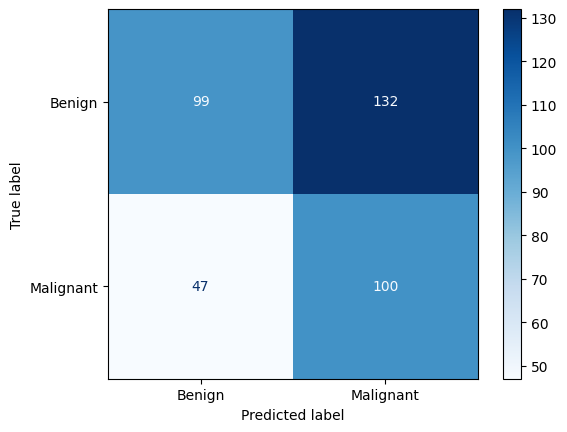

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 1: Test Accuracy = 52.65%
Epoch 1 completed in 7.71 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 52.65%)

Total training time: 7.71 minutes

Best Test Accuracy: 52.65%
[2,    10] loss: 0.722
[2,    20] loss: 0.707
[2,    30] loss: 0.684
[2,    40] loss: 0.707
[2,    50] loss: 0.708
[2,    60] loss: 0.668
[2,    70] loss: 0.687
[2,    80] loss: 0.672
[2,    90] loss: 0.696
[2,   100] loss: 0.662
[2,   110] loss: 0.685
[2,   120] loss: 0.630
[2,   130] loss: 0.665
Epoch Loss: 0.6848
Confusion Matrix:
[[202  29]
 [112  35]]
              precision    recall  f1-score   support

      Benign       0.64      0.87      0.74       231
   Malignant       0.55      0.24      0.33       147

    accuracy                           0.63       378
   macro avg       0.60      0.56      0.54       378
weighted avg       0.61      0.63      0.58       378



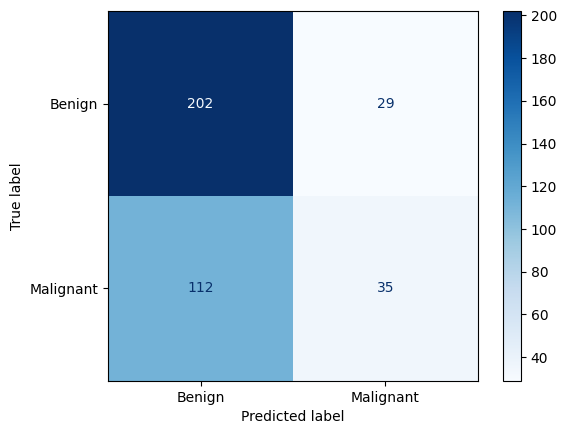

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 2: Test Accuracy = 62.70%
Epoch 2 completed in 7.66 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 62.70%)

Total training time: 15.38 minutes

Best Test Accuracy: 62.70%
[3,    10] loss: 0.658
[3,    20] loss: 0.687
[3,    30] loss: 0.679
[3,    40] loss: 0.697
[3,    50] loss: 0.683
[3,    60] loss: 0.681
[3,    70] loss: 0.676
[3,    80] loss: 0.696
[3,    90] loss: 0.683
[3,   100] loss: 0.645
[3,   110] loss: 0.669
[3,   120] loss: 0.676
[3,   130] loss: 0.667
Epoch Loss: 0.6764
Confusion Matrix:
[[201  30]
 [114  33]]
              precision    recall  f1-score   support

      Benign       0.64      0.87      0.74       231
   Malignant       0.52      0.22      0.31       147

    accuracy                           0.62       378
   macro avg       0.58      0.55      0.53       378
weighted avg       0.59      0.62      0.57       378



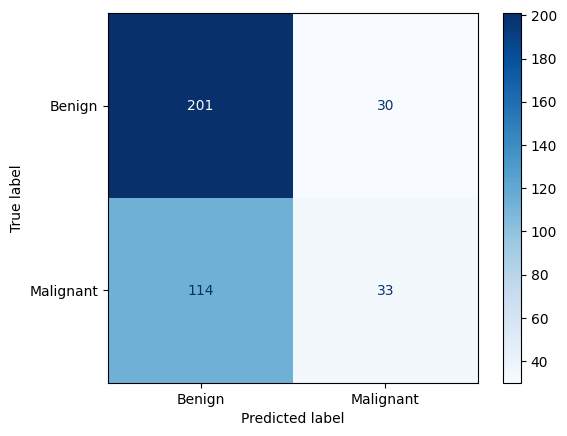

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 3: Test Accuracy = 61.90%
Epoch 3 completed in 8.03 minutes

Total training time: 23.40 minutes

Best Test Accuracy: 62.70%
[4,    10] loss: 0.685
[4,    20] loss: 0.688
[4,    30] loss: 0.656
[4,    40] loss: 0.676
[4,    50] loss: 0.681
[4,    60] loss: 0.655
[4,    70] loss: 0.660
[4,    80] loss: 0.687
[4,    90] loss: 0.645
[4,   100] loss: 0.711
[4,   110] loss: 0.672
[4,   120] loss: 0.664
[4,   130] loss: 0.703
Epoch Loss: 0.6753
Confusion Matrix:
[[184  47]
 [ 88  59]]
              precision    recall  f1-score   support

      Benign       0.68      0.80      0.73       231
   Malignant       0.56      0.40      0.47       147

    accuracy                           0.64       378
   macro avg       0.62      0.60      0.60       378
weighted avg       0.63      0.64      0.63       378



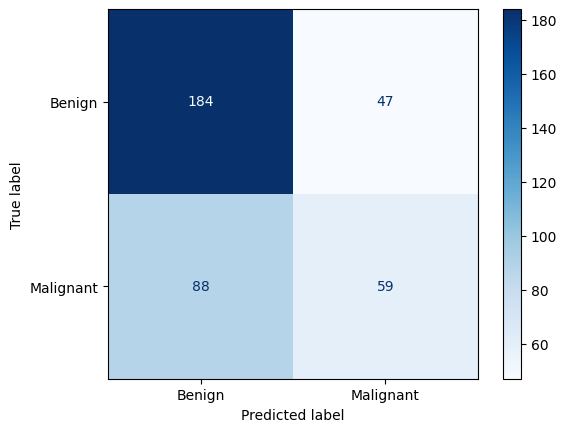

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 4: Test Accuracy = 64.29%
Epoch 4 completed in 8.01 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 64.29%)

Total training time: 31.42 minutes

Best Test Accuracy: 64.29%
[5,    10] loss: 0.689
[5,    20] loss: 0.691
[5,    30] loss: 0.644
[5,    40] loss: 0.718
[5,    50] loss: 0.633
[5,    60] loss: 0.672
[5,    70] loss: 0.647
[5,    80] loss: 0.640
[5,    90] loss: 0.673
[5,   100] loss: 0.604
[5,   110] loss: 0.635
[5,   120] loss: 0.692
[5,   130] loss: 0.681
Epoch Loss: 0.6640
Confusion Matrix:
[[154  77]
 [ 55  92]]
              precision    recall  f1-score   support

      Benign       0.74      0.67      0.70       231
   Malignant       0.54      0.63      0.58       147

    accuracy                           0.65       378
   macro avg       0.64      0.65      0.64       378
weighted avg       0.66      0.65      0.65       378



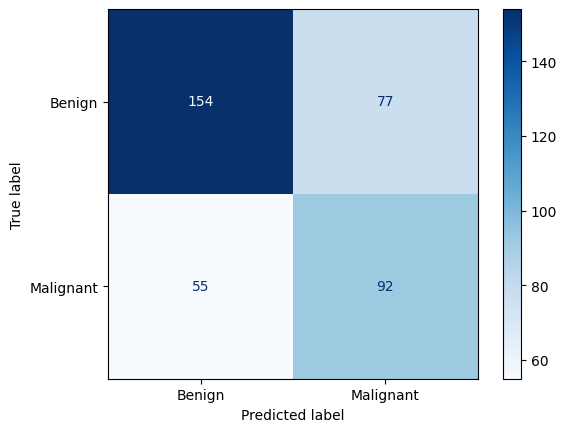

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 5: Test Accuracy = 65.08%
Epoch 5 completed in 7.94 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 65.08%)

Total training time: 39.37 minutes

Best Test Accuracy: 65.08%
[6,    10] loss: 0.652
[6,    20] loss: 0.693
[6,    30] loss: 0.668
[6,    40] loss: 0.690
[6,    50] loss: 0.657
[6,    60] loss: 0.565
[6,    70] loss: 0.677
[6,    80] loss: 0.667
[6,    90] loss: 0.696
[6,   100] loss: 0.710
[6,   110] loss: 0.651
[6,   120] loss: 0.636
[6,   130] loss: 0.654
Epoch Loss: 0.6643
Confusion Matrix:
[[231   0]
 [146   1]]
              precision    recall  f1-score   support

      Benign       0.61      1.00      0.76       231
   Malignant       1.00      0.01      0.01       147

    accuracy                           0.61       378
   macro avg       0.81      0.50      0.39       378
weighted avg       0.76      0.61      0.47       378



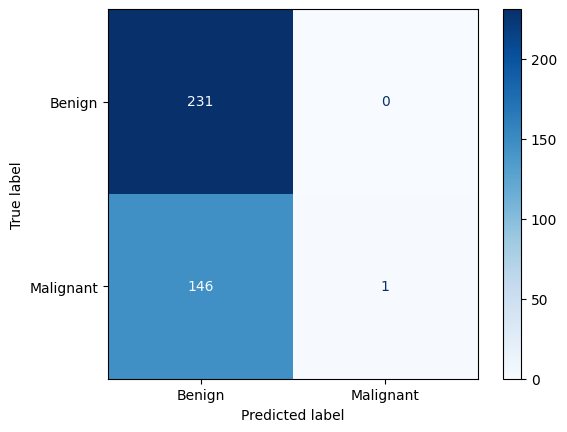

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 6: Test Accuracy = 61.38%
Epoch 6 completed in 8.11 minutes

Total training time: 47.47 minutes

Best Test Accuracy: 65.08%
[7,    10] loss: 0.663
[7,    20] loss: 0.658
[7,    30] loss: 0.666
[7,    40] loss: 0.676
[7,    50] loss: 0.710
[7,    60] loss: 0.672
[7,    70] loss: 0.699
[7,    80] loss: 0.701
[7,    90] loss: 0.672
[7,   100] loss: 0.672
[7,   110] loss: 0.650
[7,   120] loss: 0.632
[7,   130] loss: 0.675
Epoch Loss: 0.6723
Confusion Matrix:
[[180  51]
 [ 81  66]]
              precision    recall  f1-score   support

      Benign       0.69      0.78      0.73       231
   Malignant       0.56      0.45      0.50       147

    accuracy                           0.65       378
   macro avg       0.63      0.61      0.62       378
weighted avg       0.64      0.65      0.64       378



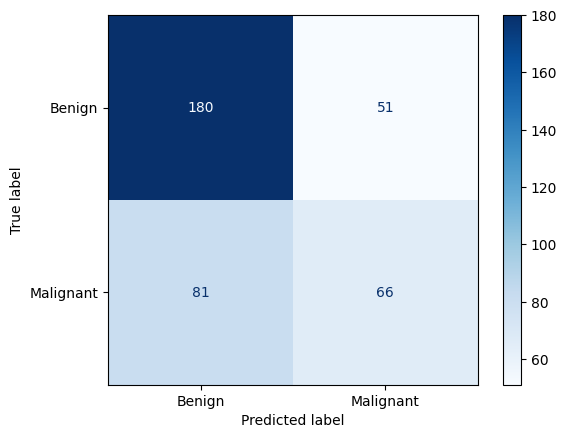

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 7: Test Accuracy = 65.08%
Epoch 7 completed in 8.18 minutes

Total training time: 55.66 minutes

Best Test Accuracy: 65.08%
[8,    10] loss: 0.622
[8,    20] loss: 0.643
[8,    30] loss: 0.648
[8,    40] loss: 0.689
[8,    50] loss: 0.639
[8,    60] loss: 0.617
[8,    70] loss: 0.672
[8,    80] loss: 0.699
[8,    90] loss: 0.643
[8,   100] loss: 0.628
[8,   110] loss: 0.702
[8,   120] loss: 0.637
[8,   130] loss: 0.698
Epoch Loss: 0.6585
Confusion Matrix:
[[205  26]
 [115  32]]
              precision    recall  f1-score   support

      Benign       0.64      0.89      0.74       231
   Malignant       0.55      0.22      0.31       147

    accuracy                           0.63       378
   macro avg       0.60      0.55      0.53       378
weighted avg       0.61      0.63      0.58       378



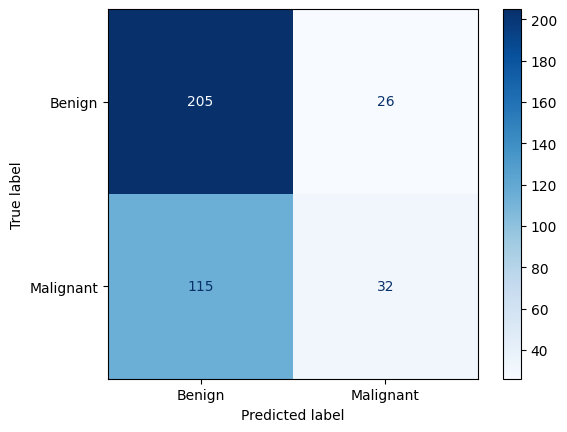

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 8: Test Accuracy = 62.70%
Epoch 8 completed in 8.07 minutes

Total training time: 63.73 minutes

Best Test Accuracy: 65.08%
[9,    10] loss: 0.658
[9,    20] loss: 0.679
[9,    30] loss: 0.704
[9,    40] loss: 0.663
[9,    50] loss: 0.620
[9,    60] loss: 0.634
[9,    70] loss: 0.690
[9,    80] loss: 0.694
[9,    90] loss: 0.649
[9,   100] loss: 0.642
[9,   110] loss: 0.639
[9,   120] loss: 0.590
[9,   130] loss: 0.713
Epoch Loss: 0.6577
Confusion Matrix:
[[178  53]
 [ 89  58]]
              precision    recall  f1-score   support

      Benign       0.67      0.77      0.71       231
   Malignant       0.52      0.39      0.45       147

    accuracy                           0.62       378
   macro avg       0.59      0.58      0.58       378
weighted avg       0.61      0.62      0.61       378



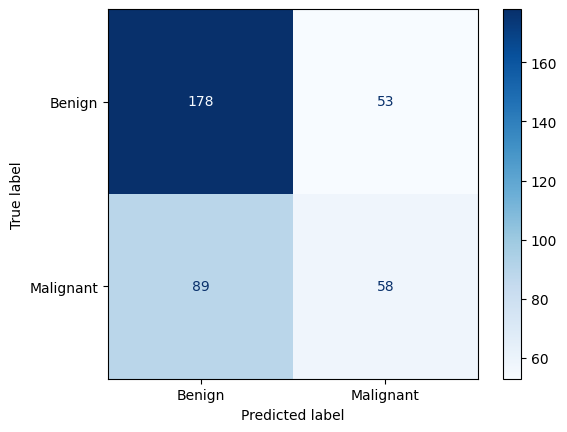

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 9: Test Accuracy = 62.43%
Epoch 9 completed in 7.66 minutes

Total training time: 71.39 minutes

Best Test Accuracy: 65.08%
[10,    10] loss: 0.649
[10,    20] loss: 0.648
[10,    30] loss: 0.637
[10,    40] loss: 0.643
[10,    50] loss: 0.706
[10,    60] loss: 0.688
[10,    70] loss: 0.705
[10,    80] loss: 0.670
[10,    90] loss: 0.670
[10,   100] loss: 0.664
[10,   110] loss: 0.626
[10,   120] loss: 0.648
[10,   130] loss: 0.637
Epoch Loss: 0.6627
Confusion Matrix:
[[201  30]
 [110  37]]
              precision    recall  f1-score   support

      Benign       0.65      0.87      0.74       231
   Malignant       0.55      0.25      0.35       147

    accuracy                           0.63       378
   macro avg       0.60      0.56      0.54       378
weighted avg       0.61      0.63      0.59       378



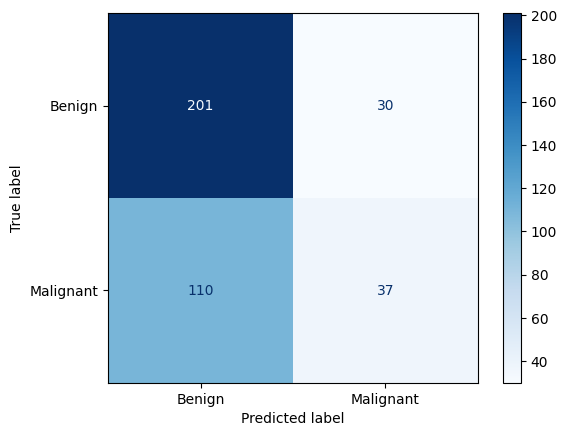

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 10: Test Accuracy = 62.96%
Epoch 10 completed in 7.64 minutes

Total training time: 79.03 minutes

Best Test Accuracy: 65.08%
[11,    10] loss: 0.654
[11,    20] loss: 0.654
[11,    30] loss: 0.594
[11,    40] loss: 0.627
[11,    50] loss: 0.697
[11,    60] loss: 0.626
[11,    70] loss: 0.654
[11,    80] loss: 0.676
[11,    90] loss: 0.646
[11,   100] loss: 0.656
[11,   110] loss: 0.652
[11,   120] loss: 0.665
[11,   130] loss: 0.702
Epoch Loss: 0.6516
Confusion Matrix:
[[218  13]
 [129  18]]
              precision    recall  f1-score   support

      Benign       0.63      0.94      0.75       231
   Malignant       0.58      0.12      0.20       147

    accuracy                           0.62       378
   macro avg       0.60      0.53      0.48       378
weighted avg       0.61      0.62      0.54       378



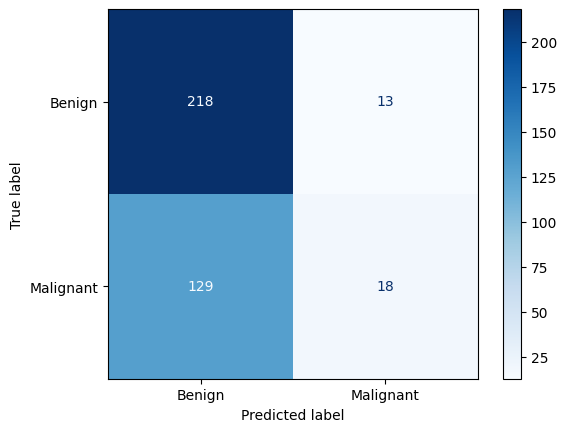

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 11: Test Accuracy = 62.43%
Epoch 11 completed in 7.75 minutes

Total training time: 86.77 minutes

Best Test Accuracy: 65.08%
[12,    10] loss: 0.678
[12,    20] loss: 0.697
[12,    30] loss: 0.667
[12,    40] loss: 0.665
[12,    50] loss: 0.644
[12,    60] loss: 0.670
[12,    70] loss: 0.647
[12,    80] loss: 0.684
[12,    90] loss: 0.662
[12,   100] loss: 0.621
[12,   110] loss: 0.667
[12,   120] loss: 0.659
[12,   130] loss: 0.649
Epoch Loss: 0.6635
Confusion Matrix:
[[143  88]
 [ 55  92]]
              precision    recall  f1-score   support

      Benign       0.72      0.62      0.67       231
   Malignant       0.51      0.63      0.56       147

    accuracy                           0.62       378
   macro avg       0.62      0.62      0.61       378
weighted avg       0.64      0.62      0.63       378



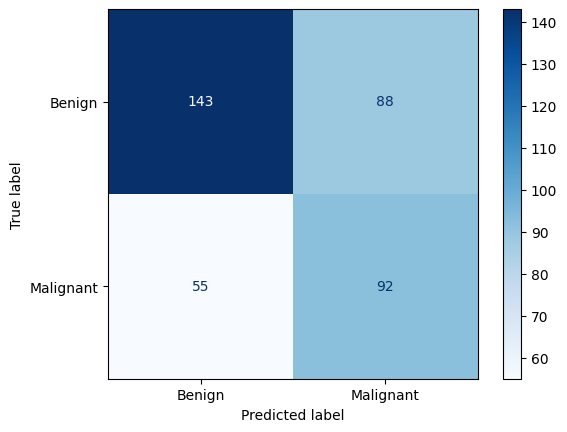

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 12: Test Accuracy = 62.17%
Epoch 12 completed in 7.63 minutes

Total training time: 94.40 minutes

Best Test Accuracy: 65.08%
[13,    10] loss: 0.644
[13,    20] loss: 0.675
[13,    30] loss: 0.618
[13,    40] loss: 0.644
[13,    50] loss: 0.633
[13,    60] loss: 0.603
[13,    70] loss: 0.701
[13,    80] loss: 0.715
[13,    90] loss: 0.674
[13,   100] loss: 0.663
[13,   110] loss: 0.646
[13,   120] loss: 0.644
[13,   130] loss: 0.606
Epoch Loss: 0.6521
Confusion Matrix:
[[171  60]
 [ 71  76]]
              precision    recall  f1-score   support

      Benign       0.71      0.74      0.72       231
   Malignant       0.56      0.52      0.54       147

    accuracy                           0.65       378
   macro avg       0.63      0.63      0.63       378
weighted avg       0.65      0.65      0.65       378



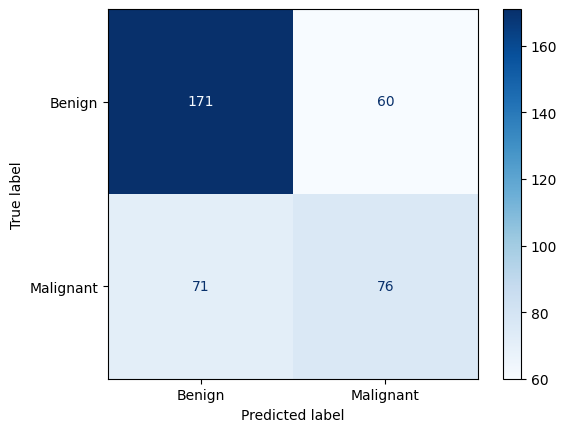

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 13: Test Accuracy = 65.34%
Epoch 13 completed in 7.61 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 65.34%)

Total training time: 102.01 minutes

Best Test Accuracy: 65.34%
[14,    10] loss: 0.653
[14,    20] loss: 0.675
[14,    30] loss: 0.587
[14,    40] loss: 0.646
[14,    50] loss: 0.682
[14,    60] loss: 0.673
[14,    70] loss: 0.668
[14,    80] loss: 0.608
[14,    90] loss: 0.647
[14,   100] loss: 0.668
[14,   110] loss: 0.691
[14,   120] loss: 0.658
[14,   130] loss: 0.655
Epoch Loss: 0.6555
Confusion Matrix:
[[200  31]
 [109  38]]
              precision    recall  f1-score   support

      Benign       0.65      0.87      0.74       231
   Malignant       0.55      0.26      0.35       147

    accuracy                           0.63       378
   macro avg       0.60      0.56      0.55       378
weighted avg       0.61      0.63      0.59       378



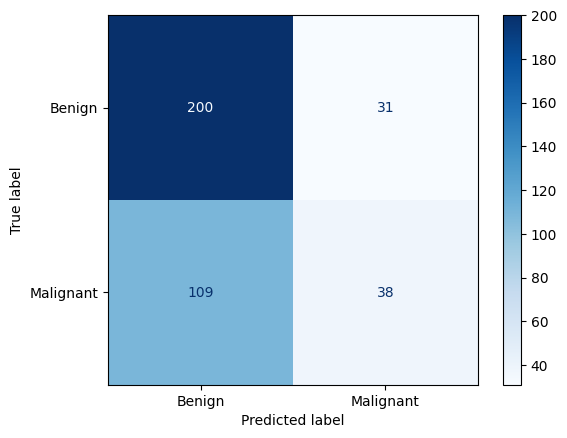

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 14: Test Accuracy = 62.96%
Epoch 14 completed in 7.97 minutes

Total training time: 109.98 minutes

Best Test Accuracy: 65.34%
[15,    10] loss: 0.675
[15,    20] loss: 0.658
[15,    30] loss: 0.656
[15,    40] loss: 0.699
[15,    50] loss: 0.635
[15,    60] loss: 0.642
[15,    70] loss: 0.649
[15,    80] loss: 0.670
[15,    90] loss: 0.601
[15,   100] loss: 0.628
[15,   110] loss: 0.714
[15,   120] loss: 0.668
[15,   130] loss: 0.589
Epoch Loss: 0.6514
Confusion Matrix:
[[161  70]
 [ 63  84]]
              precision    recall  f1-score   support

      Benign       0.72      0.70      0.71       231
   Malignant       0.55      0.57      0.56       147

    accuracy                           0.65       378
   macro avg       0.63      0.63      0.63       378
weighted avg       0.65      0.65      0.65       378



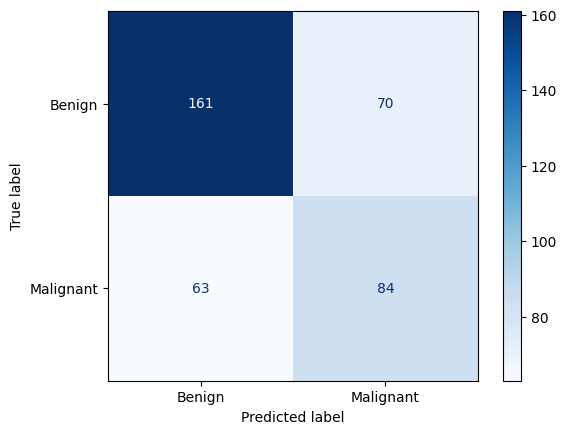

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 15: Test Accuracy = 64.81%
Epoch 15 completed in 8.03 minutes

Total training time: 118.01 minutes

Best Test Accuracy: 65.34%
[16,    10] loss: 0.570
[16,    20] loss: 0.621
[16,    30] loss: 0.646
[16,    40] loss: 0.667
[16,    50] loss: 0.666
[16,    60] loss: 0.678
[16,    70] loss: 0.675
[16,    80] loss: 0.622
[16,    90] loss: 0.672
[16,   100] loss: 0.672
[16,   110] loss: 0.652
[16,   120] loss: 0.648
[16,   130] loss: 0.647
Epoch Loss: 0.6489
Confusion Matrix:
[[157  74]
 [ 56  91]]
              precision    recall  f1-score   support

      Benign       0.74      0.68      0.71       231
   Malignant       0.55      0.62      0.58       147

    accuracy                           0.66       378
   macro avg       0.64      0.65      0.65       378
weighted avg       0.66      0.66      0.66       378



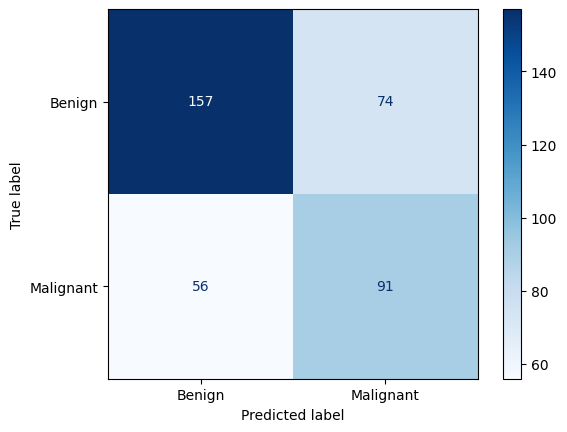

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 16: Test Accuracy = 65.61%
Epoch 16 completed in 7.90 minutes
✓ Saved model to ./custom_cnn_gputraining_layer.pth
✓ New best model saved (Accuracy = 65.61%)

Total training time: 125.92 minutes

Best Test Accuracy: 65.61%
[17,    10] loss: 0.673
[17,    20] loss: 0.653
[17,    30] loss: 0.660
[17,    40] loss: 0.638
[17,    50] loss: 0.619
[17,    60] loss: 0.660
[17,    70] loss: 0.640
[17,    80] loss: 0.610
[17,    90] loss: 0.642
[17,   100] loss: 0.635
[17,   110] loss: 0.661
[17,   120] loss: 0.665
[17,   130] loss: 0.623
Epoch Loss: 0.6444
Confusion Matrix:
[[193  38]
 [103  44]]
              precision    recall  f1-score   support

      Benign       0.65      0.84      0.73       231
   Malignant       0.54      0.30      0.38       147

    accuracy                           0.63       378
   macro avg       0.59      0.57      0.56       378
weighted avg       0.61      0.63      0.60       378



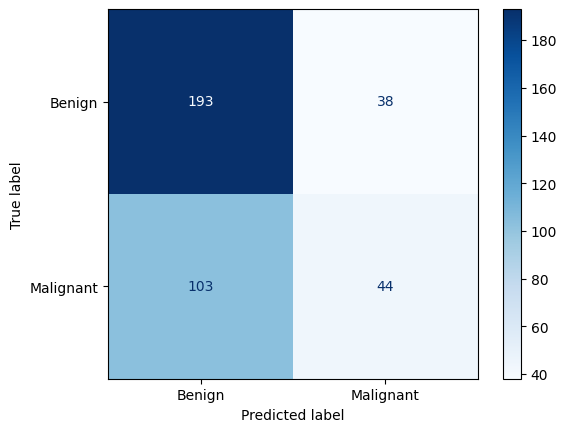

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 17: Test Accuracy = 62.70%
Epoch 17 completed in 8.06 minutes

Total training time: 133.98 minutes

Best Test Accuracy: 65.61%
[18,    10] loss: 0.625
[18,    20] loss: 0.681
[18,    30] loss: 0.675
[18,    40] loss: 0.655
[18,    50] loss: 0.610
[18,    60] loss: 0.629
[18,    70] loss: 0.679
[18,    80] loss: 0.647
[18,    90] loss: 0.664
[18,   100] loss: 0.619
[18,   110] loss: 0.689
[18,   120] loss: 0.654
[18,   130] loss: 0.636
Epoch Loss: 0.6508
Confusion Matrix:
[[175  56]
 [ 78  69]]
              precision    recall  f1-score   support

      Benign       0.69      0.76      0.72       231
   Malignant       0.55      0.47      0.51       147

    accuracy                           0.65       378
   macro avg       0.62      0.61      0.62       378
weighted avg       0.64      0.65      0.64       378



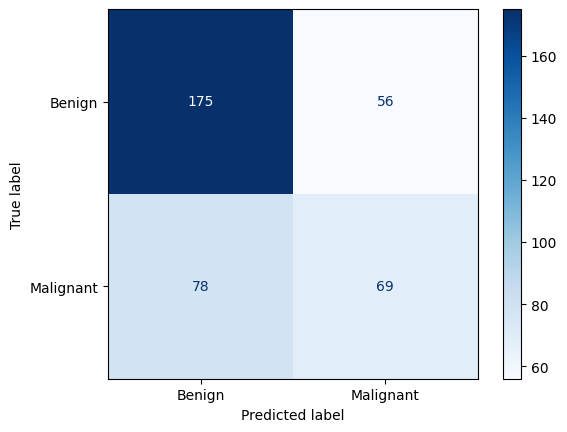

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 18: Test Accuracy = 64.55%
Epoch 18 completed in 8.14 minutes

Total training time: 142.11 minutes

Best Test Accuracy: 65.61%
[19,    10] loss: 0.621
[19,    20] loss: 0.648
[19,    30] loss: 0.630
[19,    40] loss: 0.673
[19,    50] loss: 0.613
[19,    60] loss: 0.679
[19,    70] loss: 0.653
[19,    80] loss: 0.627
[19,    90] loss: 0.685
[19,   100] loss: 0.652
[19,   110] loss: 0.598
[19,   120] loss: 0.591
[19,   130] loss: 0.691
Epoch Loss: 0.6432
Confusion Matrix:
[[201  30]
 [110  37]]
              precision    recall  f1-score   support

      Benign       0.65      0.87      0.74       231
   Malignant       0.55      0.25      0.35       147

    accuracy                           0.63       378
   macro avg       0.60      0.56      0.54       378
weighted avg       0.61      0.63      0.59       378



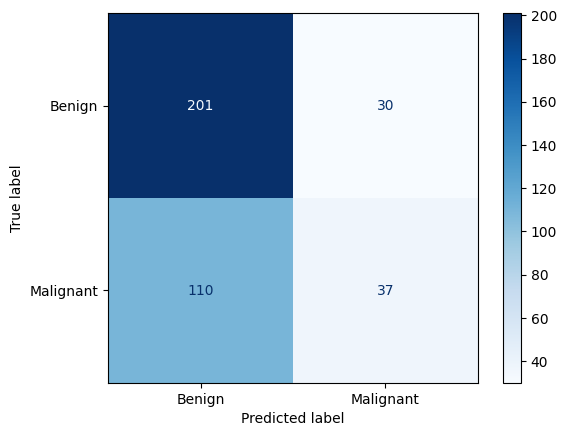

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 19: Test Accuracy = 62.96%
Epoch 19 completed in 8.29 minutes

Total training time: 150.40 minutes

Best Test Accuracy: 65.61%
[20,    10] loss: 0.688
[20,    20] loss: 0.653
[20,    30] loss: 0.624
[20,    40] loss: 0.647
[20,    50] loss: 0.669
[20,    60] loss: 0.614
[20,    70] loss: 0.685
[20,    80] loss: 0.609
[20,    90] loss: 0.654
[20,   100] loss: 0.595
[20,   110] loss: 0.657
[20,   120] loss: 0.674
[20,   130] loss: 0.658
Epoch Loss: 0.6458
Confusion Matrix:
[[195  36]
 [101  46]]
              precision    recall  f1-score   support

      Benign       0.66      0.84      0.74       231
   Malignant       0.56      0.31      0.40       147

    accuracy                           0.64       378
   macro avg       0.61      0.58      0.57       378
weighted avg       0.62      0.64      0.61       378



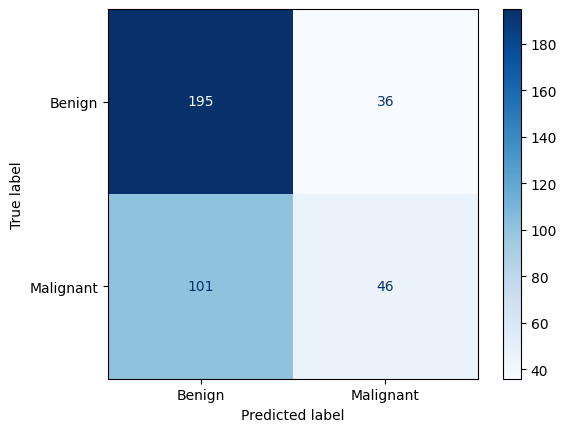

Unique predictions: [0 1]
Unique true labels: [0 1]
Epoch 20: Test Accuracy = 63.76%
Epoch 20 completed in 8.31 minutes

Total training time: 158.71 minutes

Best Test Accuracy: 65.61%


In [19]:
# Let's build our model
train(20)
# print('Finished Training')

# Test which classes performed well
# testAccuracy()
    
# Let's load the model we just created and test the accuracy per label
model = Network()
path = "custom_cnn_gputraining_layer.pth"
model.load_state_dict(torch.load(path))

model.to(device)
model.eval()
accuracy = testAccuracy()
print(f"Test Accuracy = {accuracy:.2f}%")

# Test with batch of images
# testBatch()